# **Composición con Bandas - Landsat 8**

In [ ]:
import gdown
file_id = "1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT"
output_file = "Sur_Misiones_20240403.zip"

gdown.download(f"https://drive.google.com/uc?id={file_id}", output_file)

!unzip -qq Sur_Misiones_20240403.zip

Downloading...
From (original): https://drive.google.com/uc?id=1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT
From (redirected): https://drive.google.com/uc?id=1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT&confirm=t&uuid=642193df-e473-4ac7-8d39-8ec715bdf385
To: /content/Sur_Misiones_20240403.zip
100%|██████████| 620M/620M [00:13<00:00, 44.9MB/s]


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Función para leer una banda desde un archivo TIFF
def read_band(file_path):
    # Leer la imagen en escala de grises
    band = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)
    if band is None:
        raise ValueError(f"Error leyendo la imagen en {file_path}")
    return band

# Función para normalizar el histograma usando el acumulado
def normalize_histogram(band):
    # Calcular el histograma
    # Resolución de bits del Landsat -> 2**16=65536
    hist, bins = np.histogram(band.flatten(), 65536, [0,65536])
    # Calcular el acumulado
    cdf = hist.cumsum()
    cdf_normalized = cdf * hist.max() / cdf.max()

    # Normalizar usando el CDF (distribución acumulativa de frecuencia)
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
    cdf = np.ma.filled(cdf_m, 0).astype('uint8')

    # Aplicar la transformación de normalización
    band_normalized = cdf[band]
    return band_normalized

# Función para crear una imagen RGB a partir de las bandas seleccionadas
def create_rgb_image(red_band, green_band, blue_band):
    # Asegurarse de que todas las bandas estén normalizadas
    red_normalized = normalize_histogram(red_band)
    green_normalized = normalize_histogram(green_band)
    blue_normalized = normalize_histogram(blue_band)

    # Combinar las bandas en una imagen RGB
    rgb_image = cv2.merge([blue_normalized, green_normalized, red_normalized])

    return rgb_image

In [ ]:
 # Rutas a los archivos TIFF para las bandas
red_band_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B4.TIF"
green_band_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B3.TIF"
blue_band_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B2.TIF"

# Leer las bandas
red_band = read_band(red_band_path)
green_band = read_band(green_band_path)
blue_band = read_band(blue_band_path)

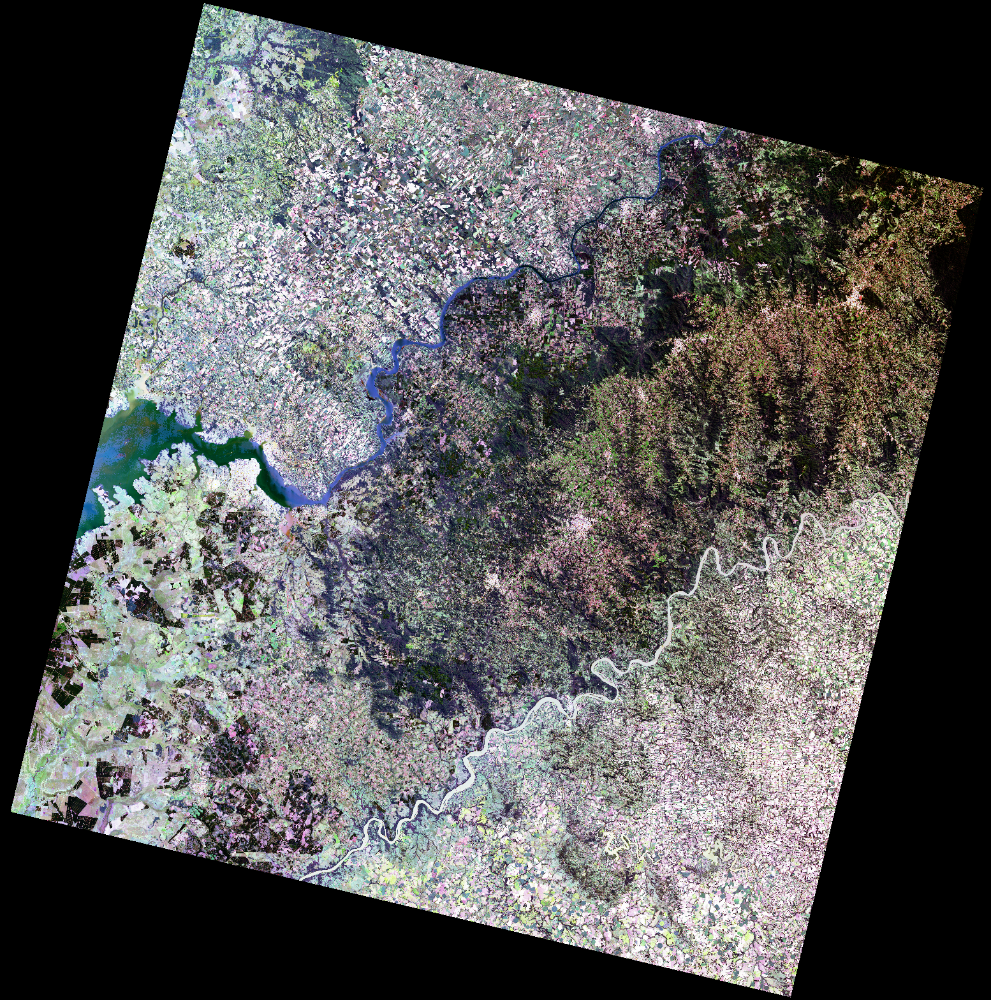

In [ ]:
# Crear la imagen RGB
rgb_image = create_rgb_image(red_band, green_band, blue_band)

# Reducir tamaño para mostrar
rgb_image = cv2.resize(rgb_image, (0, 0), fx=0.2, fy=0.2)

# Mostrar la imagen
cv2_imshow(rgb_image)

In [ ]:
# Rutas a los archivos TIF para las bandas
b7_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B7.TIF"
b6_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B6.TIF"
b4_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B4.TIF"

# Leer las bandas
b7 = read_band(b7_path)
b6 = read_band(b6_path)
b4 = read_band(b4_path)

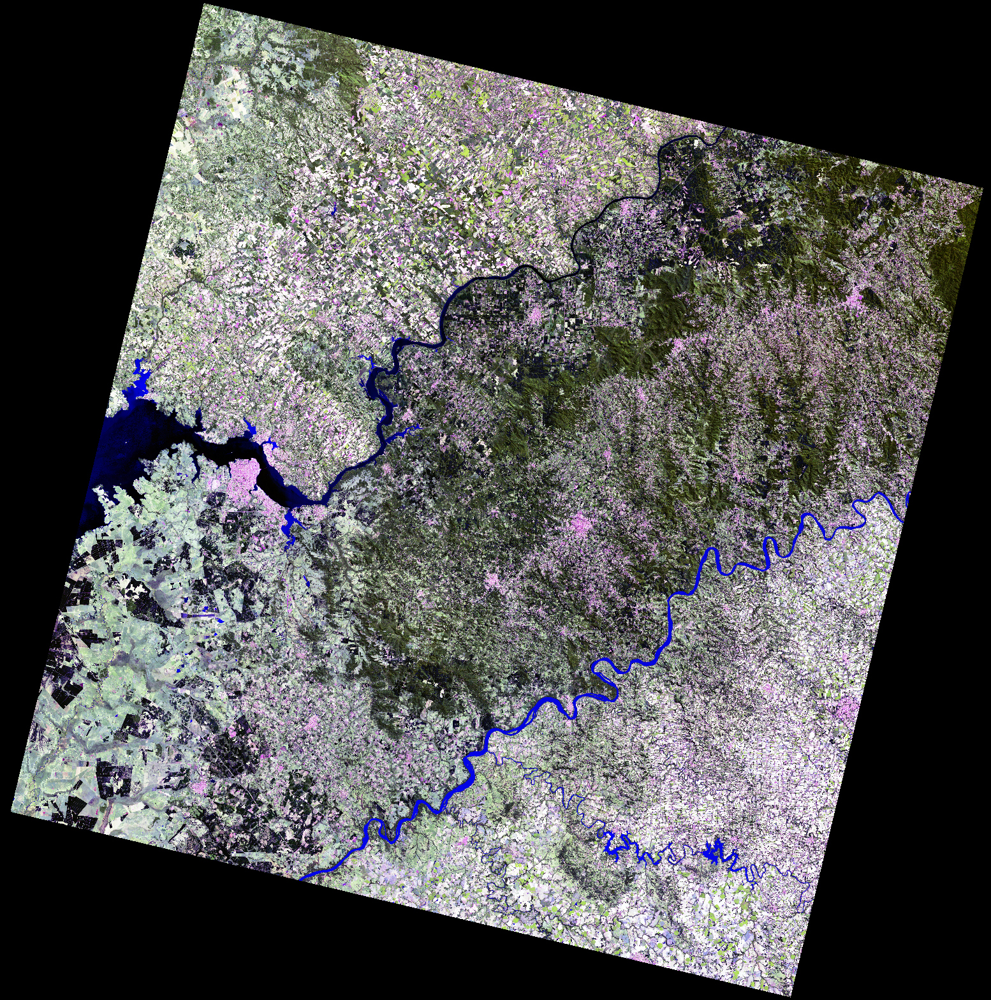

In [ ]:
falso_color = create_rgb_image(b7, b6, b4)

# Reducir tamaño para mostrar
falso_color = cv2.resize(falso_color, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(falso_color)

`create_rgb_image` llama a `normalize_histogram` para cada una de las capas que recibe. Acá abajo se sobreescribe esa función (es medio una chanchada pero bueno) para ver y comparar rápidamente el efecto de una normalización diferente. Ya conocen las herramientas, apliquen las adecuadas...

In [ ]:
def normalize_histogram(band, min_percentile=2, max_percentile=98):
    """
    Normaliza una banda de imagen utilizando umbrales de percentiles definidos por el usuario.

    Parameters:
    - band: np.ndarray. Imagen de la banda a normalizar.
    - min_percentile: float. Percentil mínimo para la normalización (por defecto 2%).
    - max_percentile: float. Percentil máximo para la normalización (por defecto 98%).

    Returns:
    - band_normalized: np.ndarray. Imagen de la banda normalizada.
    """

    # Calcular los valores de los percentiles especificados
    min_value = np.percentile(band, min_percentile)
    max_value = np.percentile(band, max_percentile)

    # Aplicar la normalización utilizando los percentiles
    band_normalized = np.clip(band, min_value, max_value)
    band_normalized = ((band_normalized - min_value) / (max_value - min_value)) * 255

    # Convertir a tipo de dato uint8
    band_normalized = band_normalized.astype(np.uint8)

    return band_normalized

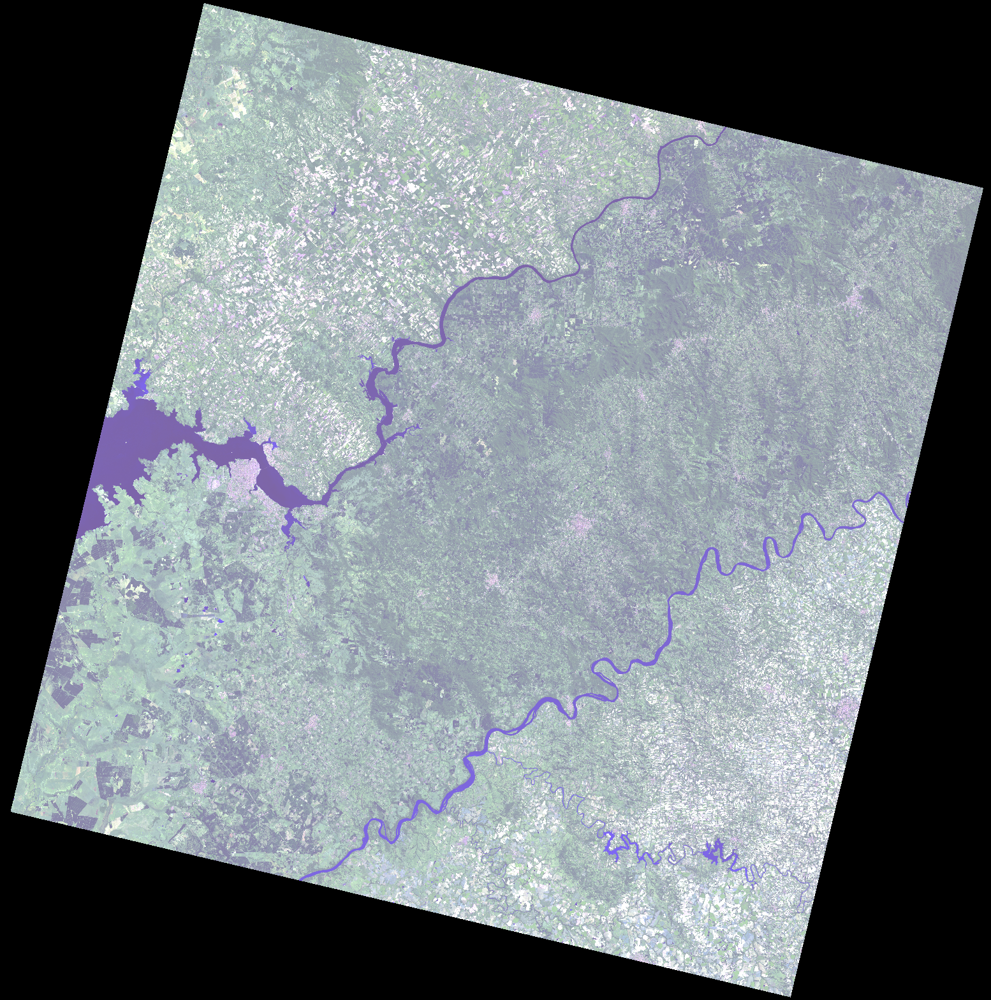

In [ ]:
falso_color = create_rgb_image(b7, b6, b4)

# Reducir tamaño para mostrar
falso_color = cv2.resize(falso_color, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(falso_color)

In [ ]:
def normalize_histogram(band, min_percentile=2, max_percentile=98):
    """
    Normaliza una banda de imagen utilizando los percentiles sobre la distribución acumulativa de frecuencia (CDF).

    Parameters:
    - band: np.ndarray. Imagen de la banda a normalizar.
    - min_percentile: float. Percentil mínimo para la normalización (por defecto 2%).
    - max_percentile: float. Percentil máximo para la normalización (por defecto 98%).

    Returns:
    - band_normalized: np.ndarray. Imagen de la banda normalizada.
    """

    # Calcular el histograma
    hist, bins = np.histogram(band.flatten(), 65536, [0, 65536])

    # Calcular la distribución acumulativa de frecuencia (CDF)
    cdf = hist.cumsum()

    # Normalizar la CDF
    cdf_normalized = cdf * 255 / cdf.max()

    # Calcular los valores de CDF correspondientes a los percentiles
    cdf_min = np.percentile(cdf_normalized, min_percentile)
    cdf_max = np.percentile(cdf_normalized, max_percentile)

    # Usar la CDF para mapear los valores originales de la imagen
    band_normalized = np.interp(band.flatten(), bins[:-1], cdf_normalized)

    # Aplicar los umbrales de normalización basados en la CDF
    band_normalized = np.clip(band_normalized, cdf_min, cdf_max)
    band_normalized = ((band_normalized - cdf_min) / (cdf_max - cdf_min)) * 255

    # Convertir a tipo de dato uint8
    band_normalized = band_normalized.reshape(band.shape).astype(np.uint8)

    return band_normalized


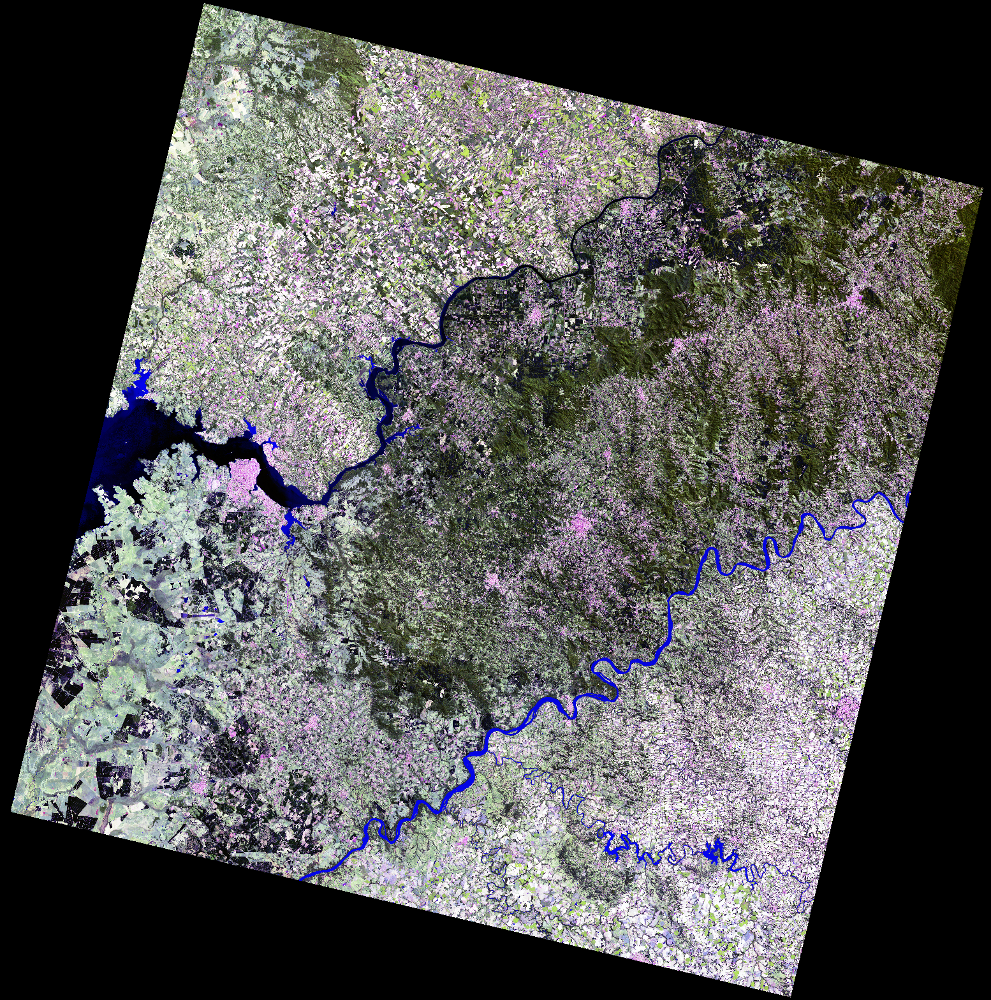

In [ ]:
falso_color = create_rgb_image(b7, b6, b4)

# Reducir tamaño para mostrar
falso_color = cv2.resize(falso_color, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(falso_color)

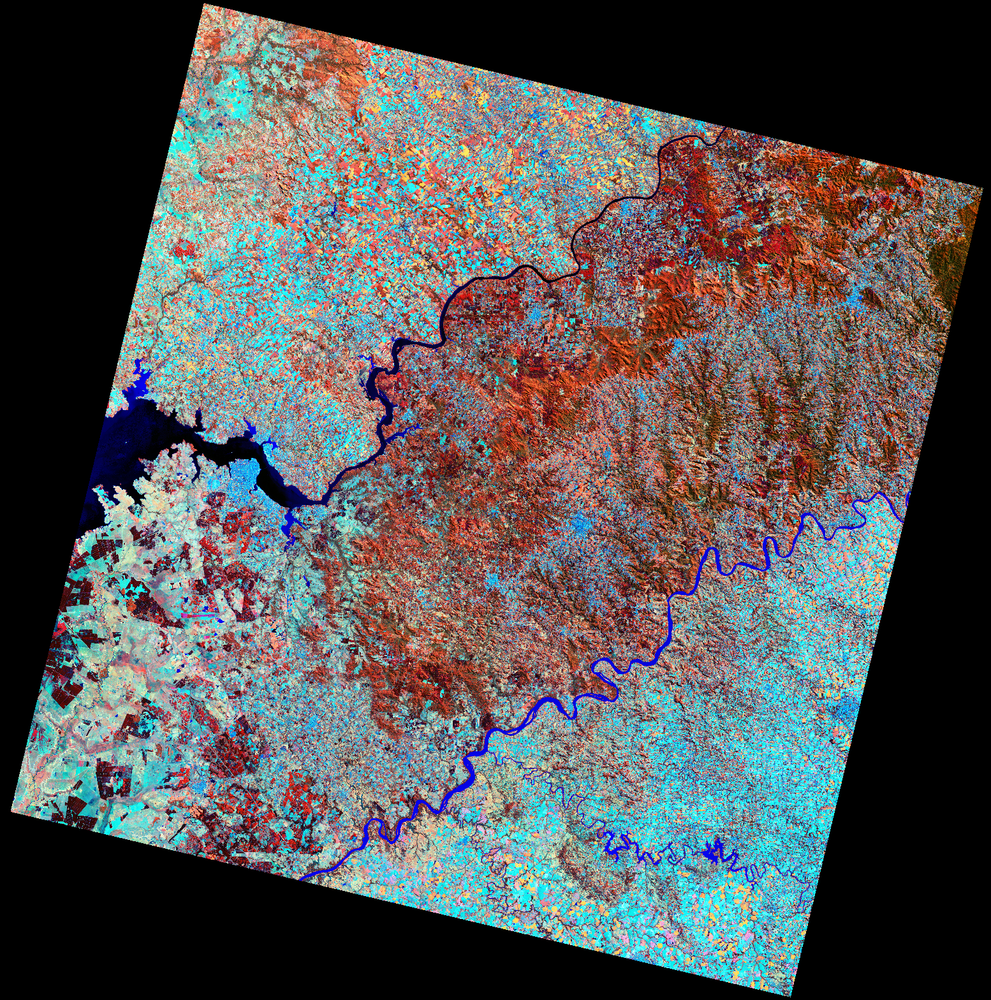

In [ ]:
b5_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B5.TIF"

# Leer las bandas
b5 = read_band(b5_path)

suelo = create_rgb_image(b5, b6, b4)

# Reducir tamaño para mostrar
suelo = cv2.resize(suelo, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(suelo)

In [ ]:
suelo.shape

(1568, 1554, 3)